In [1]:
import os
import sys
import tempfile
from pathlib import Path
from IPython.display import Image, display

# The notebook starts in docs/examples. Keep generated files outside the checkout.
repository = Path.cwd().parents[1]
workspace = tempfile.TemporaryDirectory(prefix="croak-gallery-")
(Path(workspace.name) / "examples").symlink_to(repository / "examples", target_is_directory=True)
sys.path.insert(0, str(repository / "examples"))
os.chdir(workspace.name)

In [2]:
"""Propagate a measured substrate-thickness uncertainty onto the retrieved FWHM.

For a *dispersive* retrieval, croak fits the trace through a forward model that
propagates the field through a substrate of an assumed thickness. When that thickness
is an independently measured input with its own error bar — e.g. ``9.952 ± 0.539`` µm
— the retrieved pulse, and its temporal-intensity FWHM, inherit a **systematic**
uncertainty. For thin deep-UV substrates this term can dominate the *statistical*
bootstrap, which is blind to it: every bootstrap replicate reuses the same fixed
thickness. In this example the thickness prior contributes about 0.008 fs to the
FWHM of a 3 fs pulse, about six times the 0.0013 fs parametric bootstrap spread.

This example builds a small synthetic dispersive experiment, retrieves it, and then:

* runs :func:`croak.thickness_bootstrap` to get the FWHM error from the thickness prior,
* runs a statistical :func:`croak.parametric_bootstrap` for comparison,
* combines the two error bars in quadrature (a Gaussian approximation for independent
  contributions), and
* saves the thickness-sensitivity figure.

All retrievals use the ``lbfgs-ad`` solver and the fundamental spectrum as a
spectral-match target. Without that target the fit reproduces detector noise by
putting a few per cent of the spectral energy into the outermost grid bins, where the
trace carries no signal. The trace error then drops below that of the true pulse while
the FWHM moves by up to a third, and the thickness replicates scatter between about 1
and 3.5 fs. Check :func:`croak.edge_energy_fraction` on your own retrievals; the value
printed here is negligible.

Run::

    uv run python examples/example_thickness_uncertainty.py

Writes ``thickness_uncertainty.png`` to the working directory. The comment block at the
bottom of the file shows how to run the same analysis on your own measurement from a
saved ``options.toml``.
"""

from __future__ import annotations

from math import hypot

import matplotlib
import numpy as np

matplotlib.use("Agg")

import croak
from croak.maths import wlfreq

# --- substrate prior (the measured glass thickness and its 1σ uncertainty) ----
# The motivating measurement is a *thin* DUV substrate, ~9.952 ± 0.539 µm (≈5.4 % 1σ).
# This self-contained demo instead uses a thicker slab at a longer (near-UV) wavelength,
# with the same ≈5 % relative thickness error, so it runs in well under a minute. The
# chirp a thickness error δL adds is GDD·δL; what matters for the FWHM is that phase
# relative to the pulse bandwidth, not the glass thickness itself.
CENTRAL_THICKNESS = 100.0e-6  # L0 (m)
THICKNESS_SIGMA = 5.0e-6  # σ_L (m) — ≈5 %, matching the DUV case's relative error
MATERIAL = "SiO2"
NPOINTS = 20  # depth-quadrature nodes through the slab
# lbfgs-ad fits the field by L-BFGS with an autodiff gradient, starting from the
# guess. The default warm-lbfgs runs the same fit after a COPRA warm-up that has no
# spectral penalty; here that warm-up already fits some noise, and warm-lbfgs ends
# at 3.16 fs with a trace error below that of the true pulse.
ALGORITHM = "lbfgs-ad"


def make_dispersive_experiment() -> dict:
    """Synthesise a short near-UV pulse propagated through ``CENTRAL_THICKNESS``."""
    grid = croak.Grid(256, dt=0.5e-15)
    omega0 = float(wlfreq(300e-9))  # near-UV carrier
    ew = croak.gaussian_pulse(grid, 3e-15)  # transform-limited
    delays = np.linspace(-45e-15, 45e-15, 80)
    trace = croak.maketrace(
        grid.omega,
        delays,
        ew,
        "pg",
        material=MATERIAL,
        thickness=CENTRAL_THICKNESS,
        npoints=NPOINTS,
        omega0=omega0,
    )
    return {"grid": grid, "omega0": omega0, "ew": ew, "delays": delays, "trace": trace}


def main() -> None:
    exp = make_dispersive_experiment()
    grid, omega0, delays = exp["grid"], exp["omega0"], exp["delays"]
    # A touch of detector noise so the *statistical* bootstrap is non-trivial and the
    # comparison with the thickness systematic is meaningful.
    measured = croak.NoiseModel(sigma=0.005).draw(
        exp["trace"], np.random.default_rng(7)
    )

    # The independently measured fundamental spectrum (here the exact one, on the
    # retrieval grid). Supplying it switches on the default spectral-match penalty
    # (reg_spectrum), which ties the retrieved spectral amplitude to the measured
    # band. The grid spans twice the carrier frequency, so most trace rows hold only
    # noise; without the penalty the fit reproduces that noise by putting a few per
    # cent of the energy in the outermost grid bins, which moves the FWHM by up to a
    # third. The same solver settings go to every retrieval below.
    solver = {"algorithm": ALGORITHM, "spectrum_target": np.abs(exp["ew"]) ** 2}

    # --- base dispersive retrieval at the central thickness L0 ---
    result = croak.retrieve(
        measured,
        grid.omega,
        delays,
        "pg",
        guess=croak.gaussian_pulse(grid, 4e-15),  # deliberately not the truth
        omega0=omega0,
        material=MATERIAL,
        thickness=CENTRAL_THICKNESS,
        npoints=NPOINTS,
        maxiters=150,
        progress=False,
        rng=np.random.default_rng(0),
        **solver,
    )
    pr = croak.process_result(result, measured=measured)
    # Fraction of spectral energy in the outermost grid bins: a few per cent here
    # would signal the noise-fitting failure described in the module docstring.
    edge = croak.edge_energy_fraction(result.spectrum)
    print(
        f"Base retrieval: R = {result.error:.4%},"
        f"  FWHM = {pr.fwhm_retr / 1e-15:.2f} fs,  edge energy = {edge:.1e}"
    )

    # --- systematic: propagate the measured substrate-thickness prior ---
    thick = croak.thickness_bootstrap(
        result,
        measured,
        central_thickness=CENTRAL_THICKNESS,
        thickness_sigma=THICKNESS_SIGMA,
        material=MATERIAL,
        npoints=NPOINTS,
        n_resamples=40,
        maxiters=120,
        collect_profiles=True,
        rng=np.random.default_rng(0),
        **solver,
    )
    print(thick.summary())

    # --- statistical: parametric bootstrap for comparison (noise from the residual) ---
    stat = croak.parametric_bootstrap(
        result,
        noise=croak.noise_from_residual(measured, result),
        material=MATERIAL,
        thickness=CENTRAL_THICKNESS,
        npoints=NPOINTS,
        n_resamples=40,
        maxiters=120,
        rng=np.random.default_rng(1),
        **solver,
    )
    print(stat.summary())

    # --- total error budget: independent terms add in quadrature ---
    total_pm = hypot(thick.plus_minus, stat.plus_minus)
    print(
        f"Total: FWHM = {thick.point_estimate / 1e-15:.3f} "
        f"± {total_pm / 1e-15:.3f} fs "
        f"(stat ⊕ thickness; thickness {thick.plus_minus / 1e-15:.3f} fs, "
        f"stat {stat.plus_minus / 1e-15:.4f} fs)"
    )

    truth_fwhm = croak.maths.fwhm(grid.t, np.abs(grid.ifft(exp["ew"])) ** 2)
    print(f"Generating FWHM = {truth_fwhm / 1e-15:.2f} fs; compare bias with spread.")
    fig = croak.plot_thickness_sensitivity(thick, truth=truth_fwhm)
    fig.savefig("thickness_uncertainty.png", dpi=110)
    print("Wrote thickness_uncertainty.png")


if __name__ == "__main__":
    main()


# ---------------------------------------------------------------------------
# Running this on your own data (an options.toml saved from the GUI)
# ---------------------------------------------------------------------------
# A saved session already records the loader, preprocessing and a dispersive
# retrieval (material, central thickness, quadrature, solver). Set the uncertainty
# method to "thickness" with your measured 1σ and replay it headlessly:
#
#     from dataclasses import replace
#
#     import croak
#
#     options = croak.SessionOptions.from_toml("options.toml")
#     options = options.with_(
#         uncertainty=replace(
#             options.uncertainty, method="thickness", thickness_sigma_um=0.539
#         )
#     )
#     session = croak.run_session(
#         options, stages=("load", "preproc", "retrieve", "uncertainty")
#     )
#     print(session.uncertainty.summary())
#
# The central thickness is options.retrieve.thickness_um (the retrieval must be
# dispersive). To call croak.thickness_bootstrap yourself instead, pass it
# session.result and session.tracedata.trace together with the same material,
# npoints and algorithm the retrieval used. In the GUI this is stage 5, method
# "thickness": set "Thickness σ (µm)" and click Estimate.


Base retrieval: R = 0.3544%,  FWHM = 2.97 fs,  edge energy = 8.3e-18


FWHM = 2.97 ± 0.01 fs (1σ from substrate thickness 100.000 ± 5.000 µm, systematic, B=40)


FWHM = 2.97 ± 0.00 fs (1σ statistical, parametric, B=40, warm-started; systematic uncertainty not included)
Total: FWHM = 2.965 ± 0.008 fs (stat ⊕ thickness; thickness 0.008 fs, stat 0.0017 fs)
Generating FWHM = 3.00 fs; compare bias with spread.
Wrote thickness_uncertainty.png


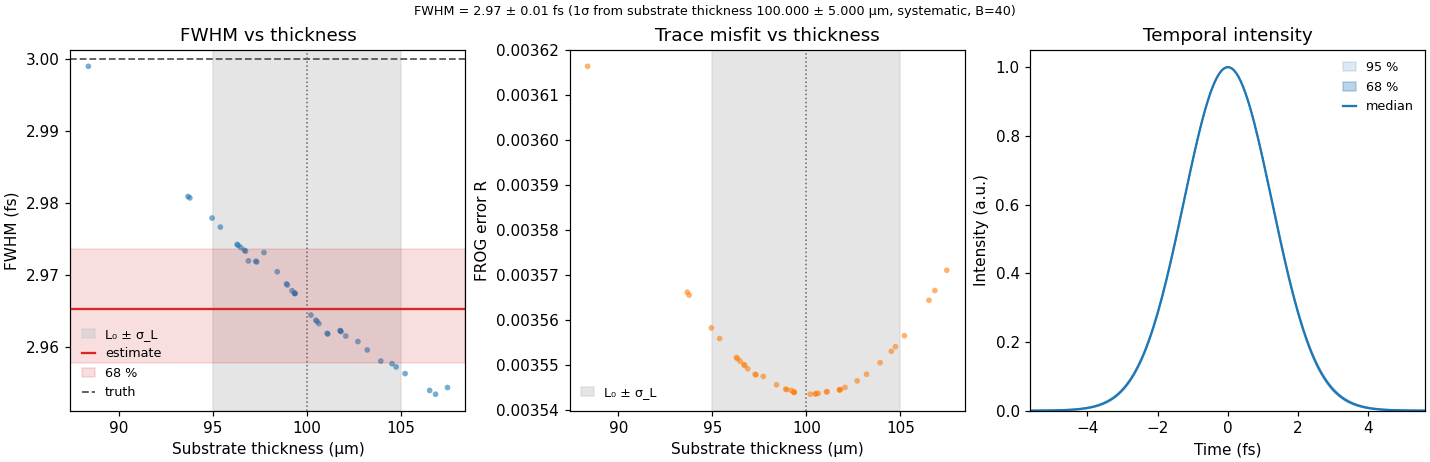

In [3]:
display(Image(filename="thickness_uncertainty.png"))